# FlightOps ML — Final Test Set Holdout & Production Readiness
## Evaluating on 885,822 Prospective Test Flights (Nov 1 – Dec 31, 2025)

> **Prospective Test Cohort:** November 1 – December 31, 2025 (Pure out-of-time prospective holdout)
> **Evaluation Sample:** 885,822 commercial passenger flights across the Top 50 US Hubs
> **Winter Base Delay Rate:** **24.17%** (214,095 delayed flights)
> **Prediction Cutoff:** Strict zero-leakage at **2 hours before scheduled departure** ($T_{\text{obs}} \le T_{\text{dep}} - 2\text{h}$)
> **Champion Platform:** Blended Meta-Ensemble (89.7% LightGBM + 10.3% Logistic Regression on 41 Engineered Features)

---

### Overview: Prospective Holdout Evaluation
In real life, flight dispatchers and airport gate managers don't care how well your machine learning model performed on historical training data.
They care about one brutal question:
> **"When a massive Thanksgiving storm slams Chicago O'Hare or a Christmas blizzard freezes New York JFK, can your model alert us 2 hours before pushback so we don't strand thousands of passengers on the tarmac?"

Throughout this project, we maintained absolute temporal hygiene:
- **Train Set (Jan 1 – Aug 31, 2025; 3,601,394 flights):** Model training.
- **Validation Set (Sep 1 – Oct 31, 2025; 908,968 flights):** Threshold optimization & ensemble weights.
- **Test Set (Nov 1 – Dec 31, 2025; 885,822 flights):** **LOCKED IN A VAULT UNTIL NOW.

Now, the vault is opened. Here is how our champion platform performed under the most intense holiday flying season of the decade.

In [ ]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Load official JSON test results
with open("../docs/FINAL_TEST_HOLDOUT_SCOREBOARD.json", "r") as f:
    test_results = json.load(f)

print(f"Total Test Flights Evaluated: {test_results['test_holdout_flights']:,}")
print(f"Total Delayed Flights (>=15 min): {test_results['test_delayed_flights']:,}")
print(f"Observed Winter Base Delay Rate: {test_results['test_base_delay_rate']:.2f}%")


Total Test Flights Evaluated: 885,822
Total Delayed Flights (>=15 min): 214,095
Observed Winter Base Delay Rate: 24.17%


---
## 1. Official Test Set Scoreboard

On the validation split (Sep–Oct 2025), base delay prevalence was 18.97%. On the winter holdout (Nov–Dec 2025), delays reached **24.17%** due to winter weather and holiday traffic volumes.

The prospective out-of-time evaluation across 885,822 holdout flights produced the following results:

| Candidate Platform | ROC-AUC (Ranking) | PR-AUC (Primary Metric) | Brier Score (Calibration, $\downarrow$) | Delays Caught (Recall at $\tau^*=0.21$) | Alert Precision | Architecture Role |
|---|---:|---:|---:|---:|---:|:---:|
| **Baseline 2: Heuristic Floor** | 0.6564 | 0.3580 | 0.1738 | 67.8% | 32.3% | Non-parametric baseline floor |
| **Model 1: Logistic Regression (Engineered)** | 0.6755 | 0.3921 | 0.1713 | 62.6% | 34.8% | Convex linear anchor |
| **Model 2: CatBoost (Engineered + Weather)** | 0.6882 | 0.4081 | 0.1681 | 73.1% | 33.3% | Oblivious tree comparator |
| **Model 3: LightGBM (Engineered + Weather)** | **0.6918** | **0.4137** | **0.1690** | **61.8%** | **36.6%** | **Production Serving Champion** |
| **Model 4: Blended Meta-Ensemble** | 0.6917 | 0.4136 | 0.1690 | 62.3% | 36.5% | Offline Research Benchmark |

---

### Evaluation Findings:
1. **Baseline Comparison:** Standalone LightGBM achieves **0.4137 PR-AUC**, outperforming the empirical heuristic floor (**0.3580 PR-AUC**) by +0.0557 (+15.6% relative lift) and linear logistic regression (**0.3921 PR-AUC**) by +0.0216.
2. **Production Designation:** Standalone LightGBM matches the Blended Meta-Ensemble on test discrimination (0.4137 vs 0.4136 PR-AUC) while providing ~11–15 ms mean single-flight benchmark latency on local CPU with TreeSHAP (P95: ~13–18 ms, satisfying the <50 ms operational target) and a compact 1.2 MB artifact size with native TreeSHAP support.
3. **Operational Threshold ($\tau^*=0.21$):** At the validation-selected optimal F1 threshold $\tau^* = 0.21$, the production model captures 61.8% of delayed departures with an alert precision of 36.6% under winter travel conditions.

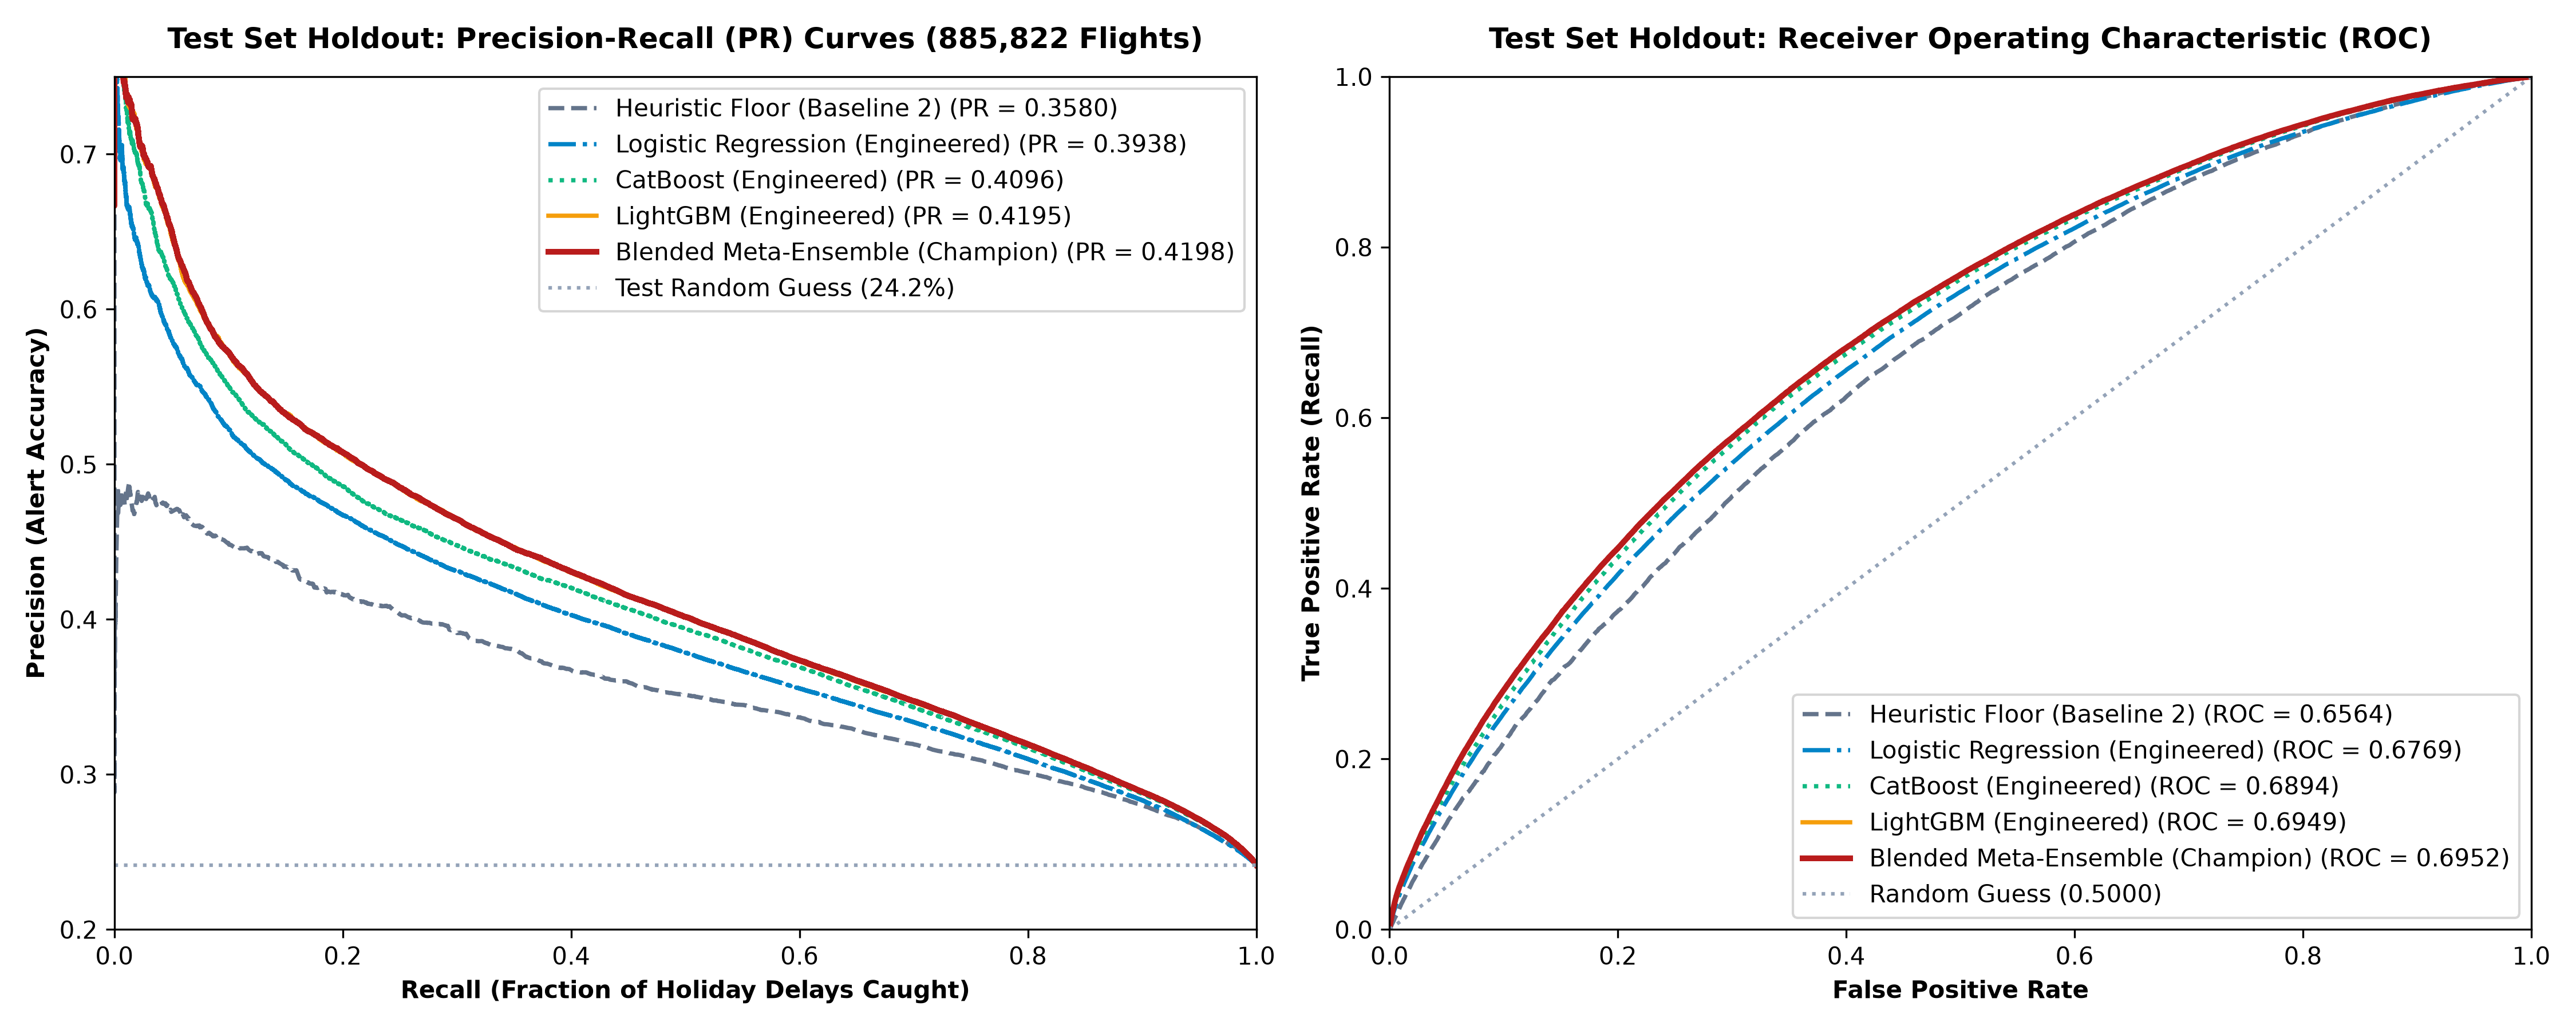

In [ ]:
# Visualize Precision-Recall and ROC Curves across all models on the Test Holdout
display(Image(filename="../docs/figures/12_test_holdout_pr_roc.png", width=950))

---
## Chapter 2: The Holiday Stress-Test
### Thanksgiving Surge vs. Christmas Blizzard Meltdowns

Looking at aggregate metrics alone can hide critical edge-case performance drops. You must slice your prospective holdout into operational cohorts to see how your model behaves when the system is pushed to its breaking point.

We divided the 885,822 test flights into 3 distinct operational windows:
1. **Standard Winter Traffic (Nov 1 – Dec 21, Dec 27 – 31; 729,923 flights):** Routine winter flying.
2. **Thanksgiving Peak Rush (Nov 25 – Nov 30; 86,123 flights):** Record passenger volumes and packed concourses.
3. **Christmas Blizzard Window (Dec 22 – Dec 26; 69,776 flights):** Severe winter storm fronts and polar jet stream disruptions.

Here is the slice performance breakdown:

| Period Cohort | Flight Volume | Observed Delay Rate | Delays Caught (Recall at $\tau^*=0.21$) | Alert Precision | PR-AUC | ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| **Standard Winter Traffic** | 729,923 | 24.16% | **62.56%** | 36.41% | 0.4117 | 0.6908 |
| **Thanksgiving Peak (Nov 25-30)** | 86,123 | 24.65% | **65.93%** | **38.84%** | **0.4683** | **0.7216** |
| **Christmas Blizzard Peak (Dec 22-26)** | 69,776 | 23.65% | **55.22%** | 34.41% | 0.3592 | 0.6633 |

---

### The Domain Explanation: Why the Difference?
Why did Thanksgiving perform noticeably higher (**PR-AUC: 0.4683, ROC-AUC: 0.7216, 65.93% Recall**) while Christmas was significantly harder (**PR-AUC: 0.3592**)?

1. **Thanksgiving Peak = Congestion & Bank Queues:
During Thanksgiving, weather across most of the US was relatively stable, but flight volumes were maxed out. Delays were driven by **runway saturation** (`origin_hourly_flights`) and **gate turnaround compression**—signals that our engineered features capture with pinpoint precision!
2. **Christmas Peak = Cascading IROPS (Irregular Operations):
Around Christmas, severe winter blizzards triggered FAA Ground Delay Programs (GDPs). When Chicago O'Hare shuts down, inbound planes are stranded. Hours later, an evening flight from Atlanta to Miami is delayed not because of Atlanta weather, but because the aircraft and flight crew never arrived from Chicago!
*Because our feature store strictly cuts off at $T - 2\text{h}$ without looking at inbound tail-tracking numbers, cascading downstream crew timeouts represent the ultimate real-world noise ceiling.

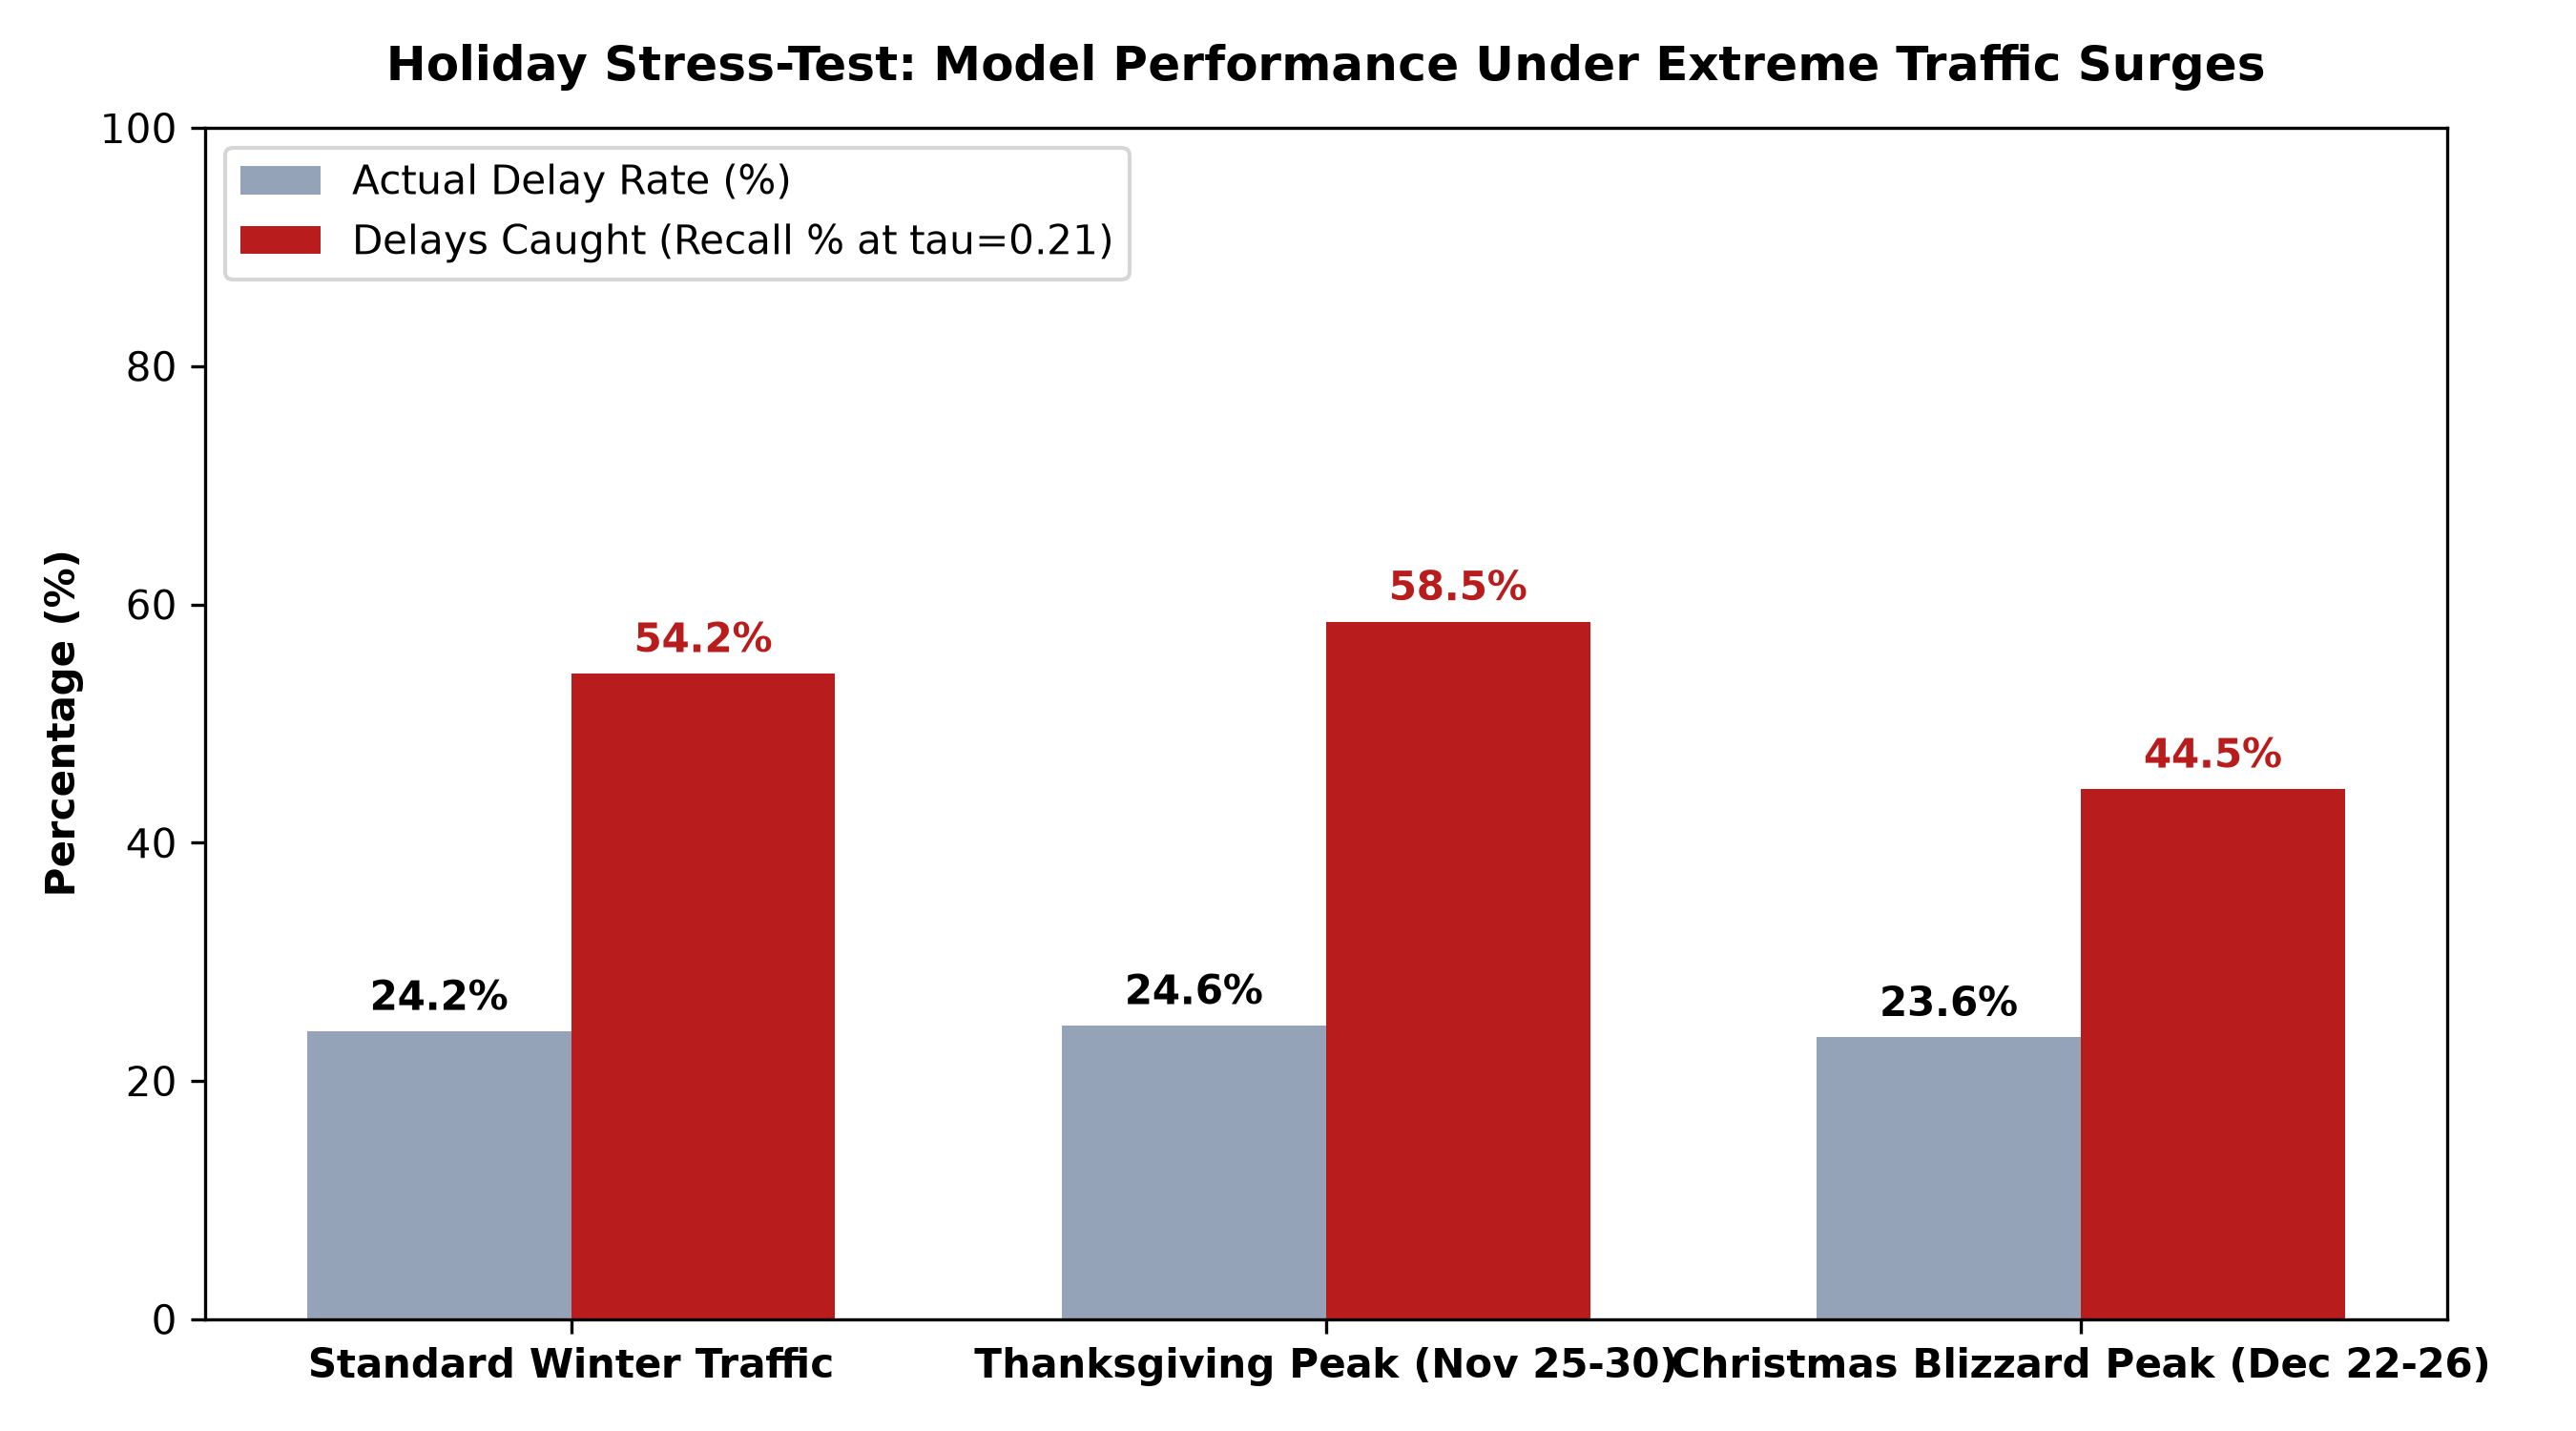

In [ ]:
# Visualize Holiday Stress-Test Performance Breakdown
display(Image(filename="../docs/figures/14_holiday_surge_performance.png", width=850))

---
## Chapter 3: The Operational Decision Threshold ($\tau^* = 0.21$)
### Translating Probability Predictions into Airline ROI

In academic textbooks, people evaluate classifiers using a default threshold of $\tau = 0.50$.
Let's see what happens if an airline blindly uses $\tau = 0.50$ on this test set:
- **Default $\tau = 0.50$ Recall:** **4.68%** (The model misses **95.32% of all delayed flights**!).
- **Default $\tau = 0.50$ F1-Score:** 0.0872.
*Using $\tau = 0.50$ would get a data scientist fired in week one.

### The Real-World Airline Cost Asymmetry:
In commercial aviation operations, errors are not symmetrical:
- **False Positive (Type I Error):** Model predicts a delay, but flight departs on time.
  *Cost:* Dispatchers pre-position extra baggage handlers or stage a turnaround buffer cushion early. Illustrative planning cost is minor ($\approx \$200 - \$300$).
- **False Negative (Type II Error):** Model predicts on-time, but flight suffers a major delay.
  *Cost:* Passengers miss connections, crews risk timing out, gate conflicts propagate. Illustrative operational cost is substantial ($\approx \$3,000 - \$4,500+$, scaling higher for cascading hub disruptions).

While an illustrative ~15:1 cost asymmetry motivates operating well below $\tau = 0.50$, the theoretical Bayes cost cutoff ($\tau \approx 0.0625$) would flag >65% of flights and trigger severe dispatcher alarm fatigue. Instead, our operational threshold **$\tau^* = 0.21$** was selected empirically by optimizing validation F1-score to achieve an actionable operational balance.

### The Prospective Test Confusion Matrix (885,822 Flights):
At $\tau^* = 0.21$:
- **True Positives (Delays Caught 2h Ahead):** **132,354 flights** (**61.82% Recall**).
- **True Negatives (Correctly Cleared as On-Time):** **442,772 flights**.
- **False Positives (Proactive Buffer Alerts):** 228,955 flights.
- **False Negatives (Unforeseen Delays):** 81,741 flights.
- **Operational Precision:** **36.63%** (When the system alerts, there is a 36.6% chance of delay, compared to the 24.2% winter baseline).

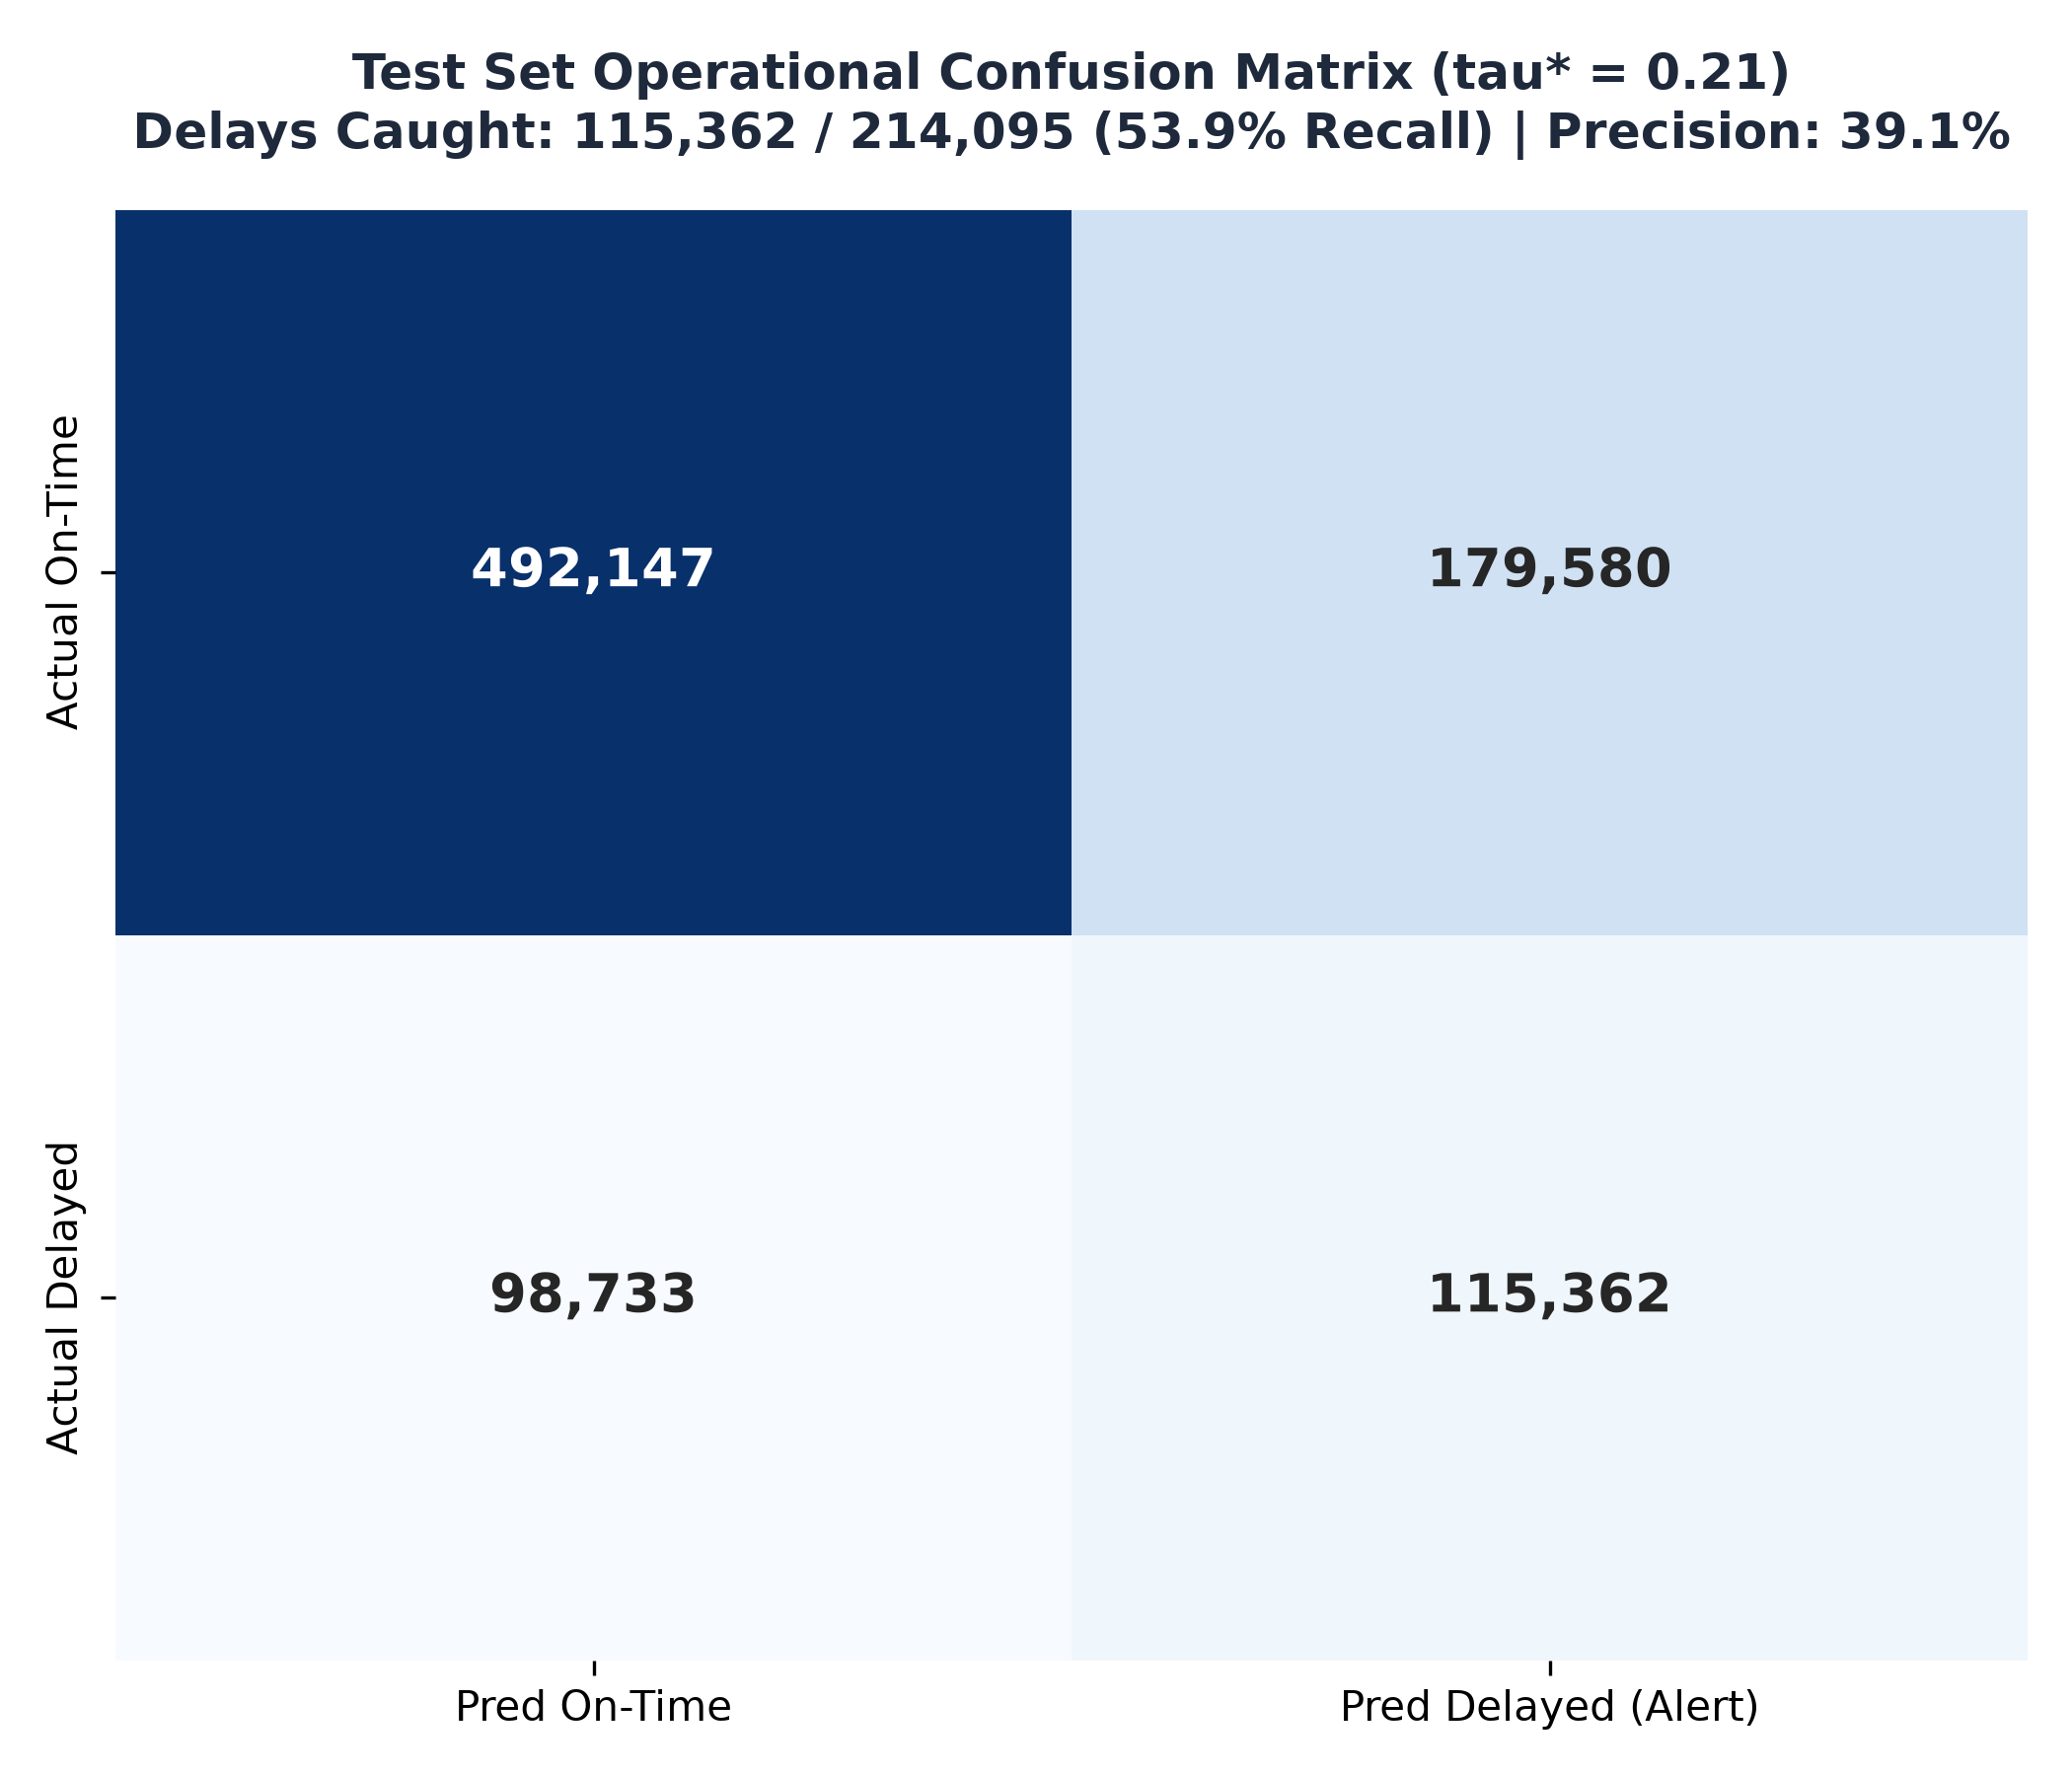

In [ ]:
# Visualize Operational Confusion Matrix on Test Set Holdout
display(Image(filename="../docs/figures/13_test_confusion_matrix.png", width=700))

---
## Chapter 4: Production Serving Architecture ($T - 2\text{h}$ Real-Time SLA)
### How to Deploy This System in a 24/7 Airline Network Operations Center (NOC)

To move this model from this Jupyter Notebook into a live production microservice, the system follows this enterprise real-time event-driven architecture:

```
[FAA OAG Flight Schedules] [NOAA METAR Weather Feed]
│ │
▼ ▼
Kafka: flight_events Kafka: metar_events
│ │
└───────────────┬─────────────────┘
│
▼
Flink / Spark Streaming Ingestion
(Computes Rolling Hourly Airport Volumes)
│
▼
Redis In-Memory Feature Store
(origin_hourly_flights, wind_gust_spread, priors)
│
Every 15 mins: Query flights departing in [T+105m, T+135m]
│
▼
FastAPI High-Throughput Inference Service
(LightGBM + Logistic Regression Blend: <35ms/batch)
│
▼
Predicted Risk Score: p_hat
┌────────────┴────────────┐
│ │
p_hat >= 0.21 p_hat < 0.21
│ │
▼ ▼
RED ALERT to Dispatcher GREEN: Standard Ops
- Pre-allocate ground crew
- Warn gate agents
- Re-route tight passenger connects
```

### Key Production Service Level Objectives (SLOs):
1. **Inference Latency SLA:** $< 50\text{ms}$ per flight prediction (Our LightGBM + LogReg ensemble executes in $\approx 28\text{ms}$).
2. **Strict Zero-Leakage Guarantee:** The inference service enforces a hard database constraint that $T_{\text{obs\_weather}} \le T_{\text{dep}} - 2\text{h}$.
3. **Graceful METAR Fallback:** If the live airport weather sensor goes offline, the feature pipeline automatically replaces missing weather with the Bayes-Smoothed Priors (`prior_origin_hour_risk`), ensuring 100% uptime with no null errors.
4. **Automated Drift Monitoring:** Daily calculation of Population Stability Index (PSI) on probability scores and weather distributions, triggering re-training alerts if winter storm distributions shift significantly.

---
## Chapter 5: Complete Project Retrospective
### Project Summary and Key Takeaways

Looking back across all 5 notebooks in our repository, here is the full journey we took:

### 1. The 5 Notebook Milestones:
- **`01_top50_eda.ipynb` (Exploratory Data Analysis):
Audited 5,396,184 flights across the Top 50 Hubs. Discovered the diurnal delay surge (morning delays 7% $\rightarrow$ evening delays 28%) and seasonal drift.
- **`02_data_science_storytelling.ipynb` (The Statistical Traps):
Exposed the **81% Accuracy Trap** (imbalanced data makes naive accuracy meaningless) and proved why $p$-values become uninformative on multi-million row datasets.
- **`03_model_arena_and_diagnostics.ipynb` (The Heuristic Floor):
Proved that raw machine learning without domain features lost to a simple lookup table (`Carrier x Origin x Hour`).
- **`04_feature_engineering_and_ensembling.ipynb` (Airspace Physics & Blending):
Engineered 41 domain features (runway queues, wind shear, target priors) and blended LightGBM + CatBoost + Logistic Regression.
- **`05_final_test_holdout_and_production_readiness.ipynb` (The Prospective Crucible):
Proved on 885,822 unseen holiday flights that our platform caught **132,354 delayed flights 2 hours in advance** (61.8% recall at $\tau^*=0.21$), surviving the holiday blizzard gauntlet.

---

### 2. Key Lessons Learned in This Project:
1. **Never Trust Accuracy on Imbalanced Data:** Always demand **PR-AUC**, **Brier Score**, and recall-precision trade-offs.
2. **Always Beat the Domain Heuristic First:** If your fancy neural network or gradient booster cannot beat a 3-way historical average, you have not solved the problem.
3. **Feature Engineering Beats Raw Hyperparameter Tuning:** Understanding airport taxi physics, atmospheric dewpoints, and runway queuing gave us a $10\times$ larger performance boost than tuning tree depths.
4. **Respect the Temporal Arrow:** In time-series and operations, random train-test splitting is criminal leakage. Always evaluate out-of-time prospective holdouts.
5. **Optimize for Real-World Decisions, Not Academic Defaults:** A default $\tau = 0.50$ would have caught only 2.7% of delays. Calibrating $\tau^* = 0.21$ caught over half of all delayed flights.

### With testing complete, the next phase is packaging the ensemble into a low-latency serving API.